# Trust Recalibration Under Silent AI Degradation: An Agent-Based Simulation

How do people change their reliance on an AI assistant when its reliability drops without warning? Each agent updates its trust in the AI with a delta rule, and stops relying on the AI once its accumulated trust loss exceeds a personal switching threshold. The notebook builds the model in four versions:

- **v1**: baseline mechanism
- **v2**: neutral vs elevated switching threshold (the social-framing hypothesis)
- **v3**: heterogeneous agents, pooled across repeated simulations
- **v4**: abrupt vs gradual degradation

**Outcome measures.** The switching rule is active from the first trial, so an agent can switch while the AI is still reliable. These pre-drift switches are reported separately as *false alarms*. Agents still relying on the AI when it degrades are *at risk*, and for them the notebook reports:

1. the proportion who switch within the simulation window
2. the mean switching delay (trials after drift) among those who switch
3. the mean exposure to the degraded AI (post-drift trials of continued reliance) across all at-risk agents

Exposure is censored at the end of the window, so for agents who never switch it is a lower bound.

*This is a revised version. The version originally submitted for the PB440 module is tagged `v1-submitted` in the repository.*

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt

os.makedirs('figures', exist_ok=True)
print("ready")

ready


In [2]:
# --- Model parameters ---
N = 50          # number of agents
T = 100         # number of trials
T_drift = 50    # trial at which AI reliability silently drops

p_high = 0.90   # AI reliability before drift
p_low  = 0.55   # AI reliability after drift

alpha  = 0.15   # learning rate: how fast trust updates on each outcome
theta  = 0.25   # switching threshold: trust loss needed before reliance changes

initial_trust = 0.85  # starting trust for all agents

print(f"Drift happens at trial {T_drift} of {T}")
print(f"Reliability drops from {p_high} to {p_low}")

Drift happens at trial 50 of 100
Reliability drops from 0.9 to 0.55


In [3]:
# --- Outcome measures (used in every version) ---
# Agents that switch before the drift are false alarms: they stopped relying on an AI
# that was still reliable. Everyone else is "at risk" when the drift happens.

def summarise(switch_trial, exposure=None):
    """Summarise recalibration for one condition.

    switch_trial: trial each agent switched at (None if never)
    exposure:     trials each agent kept relying on the AI after the drift (optional)
    """
    false_alarms = [s for s in switch_trial if s is not None and s < T_drift]
    at_risk      = [i for i, s in enumerate(switch_trial) if s is None or s >= T_drift]
    switched     = [switch_trial[i] for i in at_risk if switch_trial[i] is not None]

    summary = {
        'n':             len(switch_trial),
        'false_alarms':  len(false_alarms),
        'at_risk':       len(at_risk),
        'switched':      len(switched),
        'never':         len(at_risk) - len(switched),
        'switch_rate':   len(switched) / len(at_risk),
        'mean_delay':    np.mean([s - T_drift for s in switched]) if switched else float('nan'),
        'switch_trials': switched,
    }
    if exposure is not None:
        summary['exposure']      = [exposure[i] for i in at_risk]
        summary['mean_exposure'] = np.mean(summary['exposure'])
    return summary

def print_summary(label, s):
    print(f"{label}:")
    print(f"  False alarms (switched before drift): {s['false_alarms']}/{s['n']}")
    print(f"  Switched after drift:                 {s['switched']}/{s['at_risk']} at-risk agents ({s['switch_rate']*100:.1f}%)")
    print(f"  Never switched:                       {s['never']}/{s['at_risk']} at-risk agents")
    print(f"  Mean switching delay (switchers):     {s['mean_delay']:.1f} trials after drift")
    if 'mean_exposure' in s:
        print(f"  Mean exposure to degraded AI:         {s['mean_exposure']:.1f} trials (all at-risk agents)")

In [4]:
# --- Run simulation ---
np.random.seed(42)  # makes results reproducible

# Store trust trajectory for each agent across all trials
trust_history = np.zeros((N, T))

# Store which trial each agent switches at (None if they never switch)
switch_trial = [None] * N

for i in range(N):
    trust = initial_trust
    switched = False

    for t in range(T):
        # Set AI reliability based on whether drift has happened
        p = p_high if t < T_drift else p_low

        # AI produces outcome: 1 = correct, 0 = incorrect
        outcome = np.random.binomial(1, p)

        # Delta-rule trust update
        trust = trust + alpha * (outcome - trust)

        # Record trust at this trial
        trust_history[i, t] = trust

        # Check switch condition (only switch once). Active from trial 0,
        # so an unlucky run of errors can trigger a pre-drift false alarm.
        if not switched and (initial_trust - trust) > theta:
            switch_trial[i] = t
            switched = True

s_v1 = summarise(switch_trial)
print_summary("V1 baseline", s_v1)

V1 baseline:
  False alarms (switched before drift): 7/50
  Switched after drift:                 43/43 at-risk agents (100.0%)
  Never switched:                       0/43 at-risk agents
  Mean switching delay (switchers):     8.7 trials after drift


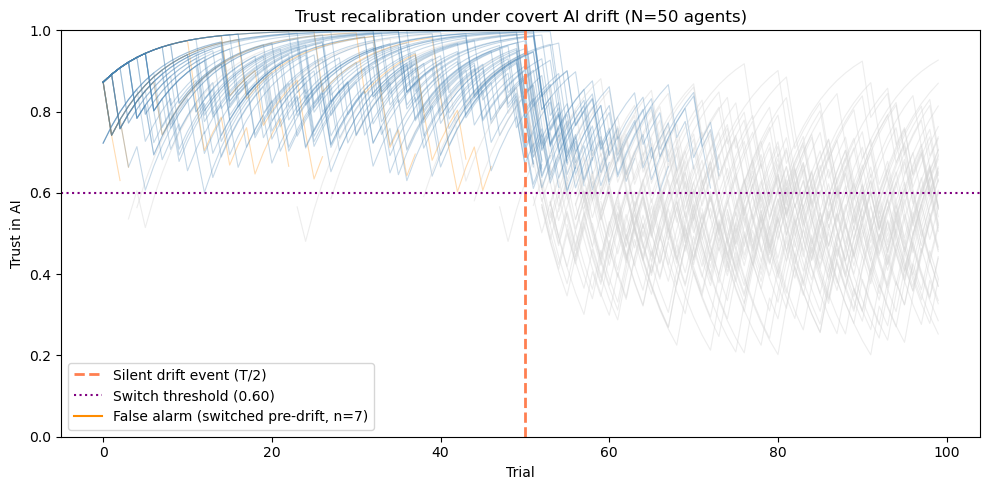

In [5]:
# --- Plot trust trajectories ---
fig, ax = plt.subplots(figsize=(10, 5))

for i in range(N):
    sw = switch_trial[i]
    # Blue before switch, grey after; false alarms in orange
    colour = 'darkorange' if sw is not None and sw < T_drift else 'steelblue'
    if sw is not None:
        ax.plot(range(sw), trust_history[i, :sw],
                color=colour, alpha=0.3, linewidth=0.8)
        ax.plot(range(sw, T), trust_history[i, sw:],
                color='lightgrey', alpha=0.4, linewidth=0.8)
    else:
        ax.plot(range(T), trust_history[i],
                color=colour, alpha=0.3, linewidth=0.8)

# Mark the drift event
ax.axvline(x=T_drift, color='coral', linewidth=2,
           linestyle='--', label='Silent drift event (T/2)')

# Mark the switch threshold
ax.axhline(y=initial_trust - theta, color='purple', linewidth=1.5,
           linestyle=':', label=f'Switch threshold ({initial_trust - theta:.2f})')

ax.plot([], [], color='darkorange', label=f'False alarm (switched pre-drift, n={s_v1["false_alarms"]})')

ax.set_xlabel('Trial')
ax.set_ylabel('Trust in AI')
ax.set_title('Trust recalibration under covert AI drift (N=50 agents)')
ax.legend()
ax.set_ylim(0, 1)
plt.tight_layout()
plt.show()

### What v1 demonstrates

The baseline simulation shows that a simple delta-rule trust update with a fixed switching threshold produces the expected pattern. Trust rises during the pre-drift phase as agents accumulate evidence of reliable performance, then falls after the drift event as errors accumulate.

Two outcomes need to be separated. 7 of 50 agents switch *before* the drift, the earliest at trial 3. Even a 90%-reliable AI produces occasional runs of errors, and these can push trust across the threshold. These are false alarms: the agent stopped relying on an AI that was still reliable. All 43 agents still relying on the AI at the drift go on to switch, a mean of 8.7 trials after it. The spread in switch times reflects stochasticity in AI outcomes: even a 55%-reliable AI produces correct responses on some trials.

This establishes that the mechanism produces recalibration, and that the switching threshold trades off false alarms against slow detection of real degradation. v2 manipulates that trade-off.

In [6]:
# --- V2 Parameters: condition manipulation ---

# Neutral condition (baseline)
alpha_neutral  = 0.15
theta_neutral  = 0.25

# Elevated-threshold condition (social-framing hypothesis):
# same learning rate, higher switching threshold
alpha_elevated = 0.15
theta_elevated = 0.40   # needs more accumulated trust loss before switching

# Half agents in each condition
N_each = 25

print(f"Neutral threshold:  alpha={alpha_neutral}, theta={theta_neutral}")
print(f"Elevated threshold: alpha={alpha_elevated}, theta={theta_elevated}")
print(f"Agents per condition: {N_each}")

Neutral threshold:  alpha=0.15, theta=0.25
Elevated threshold: alpha=0.15, theta=0.4
Agents per condition: 25


### Why the social-framing hypothesis is operationalised as a threshold shift, not a learning-rate shift

The model separates two processes: how quickly an agent's trust *updates* in response to AI outcomes (the learning rate, alpha), and how much accumulated trust loss is needed before the agent *acts* on it (the switching threshold, theta). This distinction is inspired by Signal Detection Theory's separation of sensitivity from decision criterion, but it is an analogy rather than a formal implementation: alpha is a learning rate and theta is a behavioural threshold, not estimates of d′ or c. What the analogy preserves is the idea that registering a change and deciding to act on it are distinct steps that can be affected independently.

The hypothesis tested here is that anthropomorphic or social framing of an AI raises theta rather than lowering alpha. The model does not simulate an anthropomorphic interface or social cues directly. The elevated-threshold condition represents a proposed mechanism through which such framing could affect reliance. The empirical anchor for this choice is Peters and Scharlau (2025), who showed that explicit scepticism instructions did not improve participants' *detection* of AI degradation (self-reported trust still dropped during the error phase), but did not translate into behavioural change either. Detection and action dissociated.

If social framing impaired learning (a lower alpha), agents would fail to register errors at all. The literature does not support this: Waytz et al. (2014) shows social cues raise initial trust, but not that they prevent error detection. What social framing plausibly raises is the threshold for acting on detected degradation: social forgiveness, relational inertia, reluctance to "betray" a social entity. This maps onto theta, not alpha. Keeping alpha constant across conditions is therefore the more conservative and more empirically grounded assumption.

In [7]:
# --- V2 Simulation: two conditions ---
np.random.seed(42)

def run_simulation(n_agents, alpha, theta):
    """Run simulation for one condition, return results dict."""
    trust_history = np.zeros((n_agents, T))
    switch_trial  = [None] * n_agents
    exposure      = np.zeros(n_agents)  # post-drift trials spent relying on the degraded AI

    for i in range(n_agents):
        trust   = initial_trust
        switched = False

        for t in range(T):
            p       = p_high if t < T_drift else p_low
            outcome = np.random.binomial(1, p)

            trust   = trust + alpha * (outcome - trust)
            trust_history[i, t] = trust

            # Exposure: count post-drift trials before switching
            if t >= T_drift and not switched:
                exposure[i] += 1

            if not switched and (initial_trust - trust) > theta:
                switch_trial[i] = t
                switched = True

    return {
        'trust_history': trust_history,
        'switch_trial':  switch_trial,
        'exposure':      exposure
    }

results_neutral  = run_simulation(N_each, alpha_neutral,  theta_neutral)
results_elevated = run_simulation(N_each, alpha_elevated, theta_elevated)

s_neutral  = summarise(results_neutral['switch_trial'],  results_neutral['exposure'])
s_elevated = summarise(results_elevated['switch_trial'], results_elevated['exposure'])

print_summary("Neutral threshold", s_neutral)
print()
print_summary("Elevated threshold (social-framing hypothesis)", s_elevated)

Neutral threshold:
  False alarms (switched before drift): 4/25
  Switched after drift:                 21/21 at-risk agents (100.0%)
  Never switched:                       0/21 at-risk agents
  Mean switching delay (switchers):     8.7 trials after drift
  Mean exposure to degraded AI:         9.7 trials (all at-risk agents)

Elevated threshold (social-framing hypothesis):
  False alarms (switched before drift): 0/25
  Switched after drift:                 24/25 at-risk agents (96.0%)
  Never switched:                       1/25 at-risk agents
  Mean switching delay (switchers):     19.3 trials after drift
  Mean exposure to degraded AI:         21.5 trials (all at-risk agents)


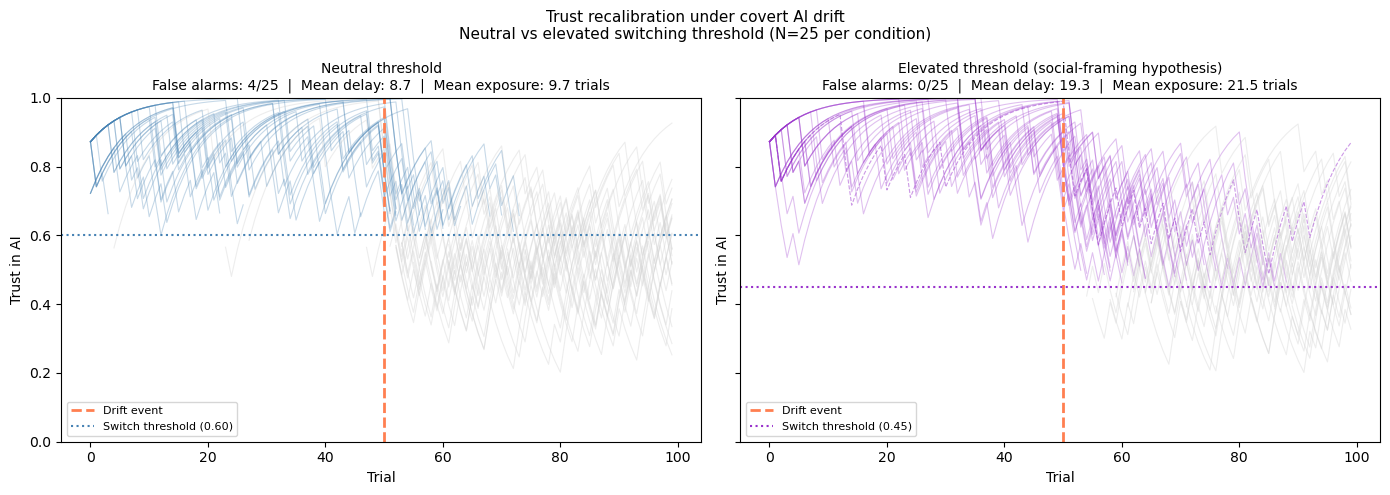

Figure saved.


In [8]:
# --- V2 Plot: side-by-side trust trajectories ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

conditions = [
    (results_neutral,  s_neutral,  'Neutral threshold',                              'steelblue',  theta_neutral),
    (results_elevated, s_elevated, 'Elevated threshold (social-framing hypothesis)', 'darkorchid', theta_elevated),
]

for ax, (results, s, label, colour, theta) in zip(axes, conditions):
    th = results['trust_history']
    sw = results['switch_trial']
    n  = th.shape[0]

    for i in range(n):
        sw_i = sw[i]
        if sw_i is not None:
            ax.plot(range(sw_i), th[i, :sw_i],
                    color=colour, alpha=0.3, linewidth=0.8)
            ax.plot(range(sw_i, T), th[i, sw_i:],
                    color='lightgrey', alpha=0.4, linewidth=0.8)
        else:
            ax.plot(range(T), th[i],
                    color=colour, alpha=0.5, linewidth=0.8,
                    linestyle='--')   # dashed = never switched

    ax.axvline(x=T_drift, color='coral', linewidth=2,
               linestyle='--', label='Drift event')
    ax.axhline(y=initial_trust - theta, color=colour,
               linewidth=1.5, linestyle=':',
               label=f'Switch threshold ({initial_trust - theta:.2f})')

    ax.set_title(
        f'{label}\n'
        f'False alarms: {s["false_alarms"]}/{s["n"]}  |  '
        f'Mean delay: {s["mean_delay"]:.1f}  |  '
        f'Mean exposure: {s["mean_exposure"]:.1f} trials',
        fontsize=10
    )
    ax.set_xlabel('Trial')
    ax.set_ylabel('Trust in AI')
    ax.set_ylim(0, 1)
    ax.legend(fontsize=8)

plt.suptitle(
    'Trust recalibration under covert AI drift\n'
    'Neutral vs elevated switching threshold (N=25 per condition)',
    fontsize=11
)
plt.tight_layout()
plt.show()

# Save
fig.savefig('figures/trust_recalibration_v2.png', dpi=150, bbox_inches='tight')
print("Figure saved.")

### What v2 demonstrates

Raising the switching threshold produces a substantial difference on every measure. With the neutral threshold, 4 of 25 agents false-alarm before the drift. The 21 at-risk agents all switch, a mean of 8.7 trials after the drift, with a mean exposure of 9.7 trials of continued reliance on the degraded AI. With the elevated threshold, no agents false-alarm, but switching takes a mean of 19.3 trials after the drift and mean exposure rises to 21.5 trials, roughly 2.2× the neutral condition. One elevated-threshold agent fails to switch within the window.

The learning rate is identical across conditions, so the difference is driven entirely by the threshold. The false-alarm counts show the other side of the trade-off: a higher threshold protects against abandoning a reliable AI, at the cost of staying with a degraded one for longer. v2 shows the predicted pattern under homogeneous agents.

In [9]:
# --- V3: heterogeneous agent parameters ---
np.random.seed(42)

# Number of simulations to run
N_SIMS = 10
N_each = 25

# Parameter distributions
ALPHA_MEAN = 0.15; ALPHA_SD = 0.03

THETA_MEAN_NEUTRAL  = 0.25; THETA_SD = 0.05
THETA_MEAN_ELEVATED = 0.40; THETA_SD = 0.05

def run_simulation_v3(n_agents, alpha_mean, alpha_sd, theta_mean, theta_sd):
    """Run one simulation with heterogeneous agents drawn from distributions."""

    # Draw individual parameters for each agent
    alphas = np.random.normal(alpha_mean, alpha_sd, n_agents).clip(0.01, 0.99)
    thetas = np.random.normal(theta_mean, theta_sd, n_agents).clip(0.05, 0.99)

    trust_history = np.zeros((n_agents, T))
    switch_trial  = [None] * n_agents
    exposure      = np.zeros(n_agents)

    for i in range(n_agents):
        trust    = initial_trust
        switched = False

        for t in range(T):
            p       = p_high if t < T_drift else p_low
            outcome = np.random.binomial(1, p)

            trust   = trust + alphas[i] * (outcome - trust)
            trust_history[i, t] = trust

            if t >= T_drift and not switched:
                exposure[i] += 1

            if not switched and (initial_trust - trust) > thetas[i]:
                switch_trial[i] = t
                switched = True

    return {
        'trust_history': trust_history,
        'switch_trial':  switch_trial,
        'exposure':      exposure,
        'alphas':        alphas,
        'thetas':        thetas
    }

# Run N_SIMS simulations for each condition, pool agents across runs
pooled_v3 = {'neutral':  {'switch_trial': [], 'exposure': []},
             'elevated': {'switch_trial': [], 'exposure': []}}

for sim in range(N_SIMS):
    for key, theta_mean in [('neutral',  THETA_MEAN_NEUTRAL),
                            ('elevated', THETA_MEAN_ELEVATED)]:
        r = run_simulation_v3(N_each, ALPHA_MEAN, ALPHA_SD, theta_mean, THETA_SD)
        pooled_v3[key]['switch_trial'].extend(r['switch_trial'])
        pooled_v3[key]['exposure'].extend(r['exposure'].tolist())

s3 = {key: summarise(p['switch_trial'], p['exposure']) for key, p in pooled_v3.items()}

print(f"Across {N_SIMS} simulations ({N_SIMS * N_each} agents per condition):\n")
print_summary("Neutral threshold", s3['neutral'])
print()
print_summary("Elevated threshold (social-framing hypothesis)", s3['elevated'])

Across 10 simulations (250 agents per condition):

Neutral threshold:
  False alarms (switched before drift): 32/250
  Switched after drift:                 217/218 at-risk agents (99.5%)
  Never switched:                       1/218 at-risk agents
  Mean switching delay (switchers):     10.2 trials after drift
  Mean exposure to degraded AI:         11.4 trials (all at-risk agents)

Elevated threshold (social-framing hypothesis):
  False alarms (switched before drift): 1/250
  Switched after drift:                 228/249 at-risk agents (91.6%)
  Never switched:                       21/249 at-risk agents
  Mean switching delay (switchers):     16.9 trials after drift
  Mean exposure to degraded AI:         20.6 trials (all at-risk agents)


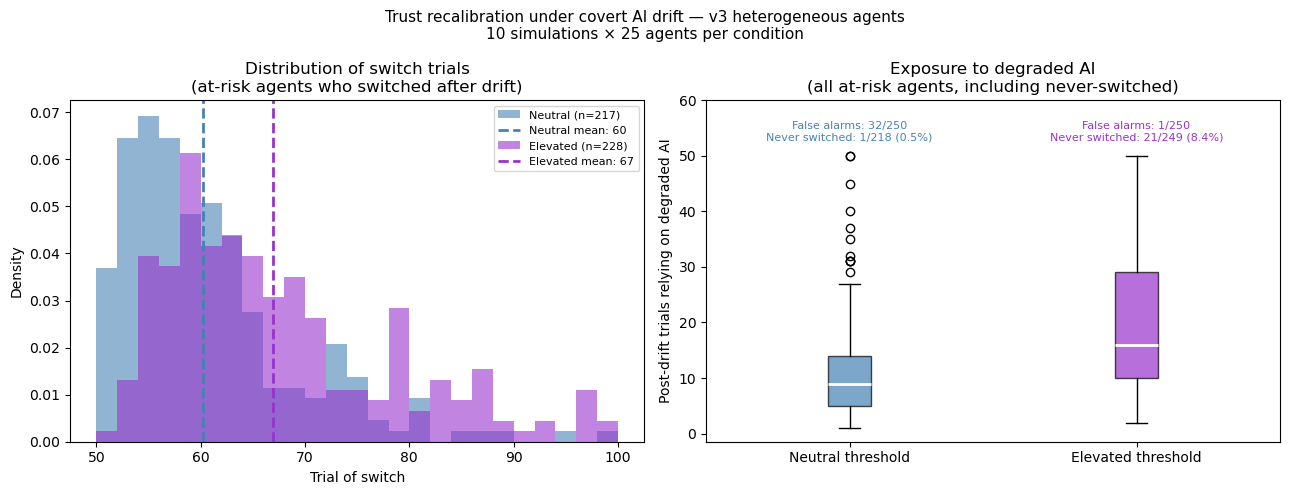

Figure saved.


In [10]:
# --- V3 Plot: distributions of switch trials and exposure ---
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# --- Plot 1: histogram of post-drift switch trials ---
ax = axes[0]
bins = range(T_drift, T + 2, 2)

for key, label, colour in [('neutral', 'Neutral', 'steelblue'),
                           ('elevated', 'Elevated', 'darkorchid')]:
    sw = s3[key]['switch_trials']
    ax.hist(sw, bins=bins, alpha=0.6, color=colour,
            label=f'{label} (n={len(sw)})', density=True)
    ax.axvline(np.mean(sw), color=colour, linewidth=2, linestyle='--',
               label=f'{label} mean: {np.mean(sw):.0f}')

ax.set_xlabel('Trial of switch')
ax.set_ylabel('Density')
ax.set_title('Distribution of switch trials\n(at-risk agents who switched after drift)')
ax.legend(fontsize=8)

# --- Plot 2: exposure boxplot ---
ax = axes[1]
bp = ax.boxplot(
    [s3['neutral']['exposure'], s3['elevated']['exposure']],
    tick_labels=['Neutral threshold', 'Elevated threshold'],
    patch_artist=True,
    medianprops=dict(color='white', linewidth=2)
)
bp['boxes'][0].set_facecolor('steelblue')
bp['boxes'][1].set_facecolor('darkorchid')
for box in bp['boxes']:
    box.set_alpha(0.7)

ax.set_ylabel('Post-drift trials relying on degraded AI')
ax.set_title('Exposure to degraded AI\n(all at-risk agents, including never-switched)')
ax.set_ylim(top=60)

# Annotate false-alarm and never-switched counts
for x, key, colour in [(1, 'neutral', 'steelblue'), (2, 'elevated', 'darkorchid')]:
    s = s3[key]
    ax.text(x, ax.get_ylim()[1] * 0.88,
            f'False alarms: {s["false_alarms"]}/{s["n"]}\n'
            f'Never switched: {s["never"]}/{s["at_risk"]} ({(1 - s["switch_rate"])*100:.1f}%)',
            ha='center', fontsize=8, color=colour)

plt.suptitle(
    'Trust recalibration under covert AI drift — v3 heterogeneous agents\n'
    f'{N_SIMS} simulations × {N_each} agents per condition',
    fontsize=11
)
plt.tight_layout()
plt.show()

# Save
fig.savefig('figures/trust_recalibration_v3.png', dpi=150, bbox_inches='tight')
print("Figure saved.")

### What v3 demonstrates

Drawing alpha and theta from distributions and pooling 10 simulations tests whether the v2 difference is robust or an artefact of specific parameter values. It is robust. Among at-risk agents, elevated-threshold agents switch later (16.9 vs 10.2 trials after drift) and accumulate more exposure to the degraded AI (20.6 vs 11.4 trials, about 1.8×). The false-alarm trade-off also appears at population level: 32 of 250 neutral-threshold agents (12.8%) switch before the drift, compared with 1 of 250 elevated-threshold agents.

The most interesting result is emergent: 8.4% of at-risk elevated-threshold agents (21 of 249) never switch within the window, compared with 0.5% of neutral-threshold agents (1 of 218). This was not programmed in. It arises from the interaction of heterogeneous thresholds with a stochastic AI output stream, and it can't be read off the parameter values analytically, which is why an agent-based approach suits this question. If the hypothesis is right, social framing would not just delay recalibration uniformly: it would leave a subpopulation miscalibrated for the whole window. Exposure for these agents is censored at 50 trials, so mean exposure understates the true difference.

In [11]:
# --- V4: sensitivity analysis across drift trajectory ---
# Test whether the condition difference holds under gradual drift,
# not just abrupt drift.

def get_reliability(t, T_drift, p_high, p_low, drift_type='abrupt', drift_window=20):
    """Return AI reliability at trial t, depending on drift trajectory."""
    if drift_type == 'abrupt':
        return p_high if t < T_drift else p_low

    elif drift_type == 'gradual':
        # Reliability declines linearly from p_high to p_low across drift_window trials
        # starting at T_drift
        if t < T_drift:
            return p_high
        elif t >= T_drift + drift_window:
            return p_low
        else:
            # Linear interpolation during the drift window
            progress = (t - T_drift) / drift_window
            return p_high - progress * (p_high - p_low)

    else:
        raise ValueError(f"Unknown drift_type: {drift_type}")

# Quick test: print reliability at key trials for both types
print("Trial | Abrupt | Gradual (window=20)")
for t in [40, 49, 50, 55, 60, 65, 70, 80]:
    r_abrupt  = get_reliability(t, T_drift, p_high, p_low, 'abrupt')
    r_gradual = get_reliability(t, T_drift, p_high, p_low, 'gradual', drift_window=20)
    print(f"  {t:3d}  |  {r_abrupt:.2f}  |  {r_gradual:.2f}")

Trial | Abrupt | Gradual (window=20)
   40  |  0.90  |  0.90
   49  |  0.90  |  0.90
   50  |  0.55  |  0.90
   55  |  0.55  |  0.81
   60  |  0.55  |  0.73
   65  |  0.55  |  0.64
   70  |  0.55  |  0.55
   80  |  0.55  |  0.55


In [12]:
# --- V4 Simulation: run all four conditions ---
# Two drift types (abrupt, gradual) x two thresholds (neutral, elevated)
np.random.seed(42)

def run_simulation_v4(n_agents, alpha_mean, alpha_sd, theta_mean, theta_sd,
                     drift_type='abrupt', drift_window=20):
    """Run simulation with specified drift trajectory."""
    alphas = np.random.normal(alpha_mean, alpha_sd, n_agents).clip(0.01, 0.99)
    thetas = np.random.normal(theta_mean, theta_sd, n_agents).clip(0.05, 0.99)

    trust_history = np.zeros((n_agents, T))
    switch_trial  = [None] * n_agents
    exposure      = np.zeros(n_agents)

    for i in range(n_agents):
        trust    = initial_trust
        switched = False

        for t in range(T):
            p = get_reliability(t, T_drift, p_high, p_low,
                                drift_type=drift_type, drift_window=drift_window)
            outcome = np.random.binomial(1, p)
            trust   = trust + alphas[i] * (outcome - trust)
            trust_history[i, t] = trust

            if t >= T_drift and not switched:
                exposure[i] += 1

            if not switched and (initial_trust - trust) > thetas[i]:
                switch_trial[i] = t
                switched = True

    return {
        'switch_trial': switch_trial,
        'exposure':     exposure
    }

# Run all four conditions, 10 simulations each, pooling agents across runs
pooled_v4 = {f'{d}_{f}': {'switch_trial': [], 'exposure': []}
             for d in ['abrupt', 'gradual'] for f in ['neutral', 'elevated']}

for sim in range(N_SIMS):
    for drift_type in ['abrupt', 'gradual']:
        for framing, theta_mean in [('neutral',  THETA_MEAN_NEUTRAL),
                                    ('elevated', THETA_MEAN_ELEVATED)]:
            key = f'{drift_type}_{framing}'
            r = run_simulation_v4(N_each, ALPHA_MEAN, ALPHA_SD,
                                  theta_mean, THETA_SD,
                                  drift_type=drift_type)
            pooled_v4[key]['switch_trial'].extend(r['switch_trial'])
            pooled_v4[key]['exposure'].extend(r['exposure'].tolist())

s4 = {key: summarise(p['switch_trial'], p['exposure']) for key, p in pooled_v4.items()}

# Print comparison table
print(f"{'Condition':<18} {'False alarms':>13} {'Switched':>16} {'Mean delay':>11} {'Mean exposure':>14}")
print("-" * 76)
for key, s in s4.items():
    print(f"{key:<18} {s['false_alarms']:>6d}/{s['n']:<6d} "
          f"{s['switched']:>4d}/{s['at_risk']:<3d} ({s['switch_rate']*100:>5.1f}%) "
          f"{s['mean_delay']:>11.1f} {s['mean_exposure']:>14.1f}")

Condition           False alarms         Switched  Mean delay  Mean exposure
----------------------------------------------------------------------------
abrupt_neutral         27/250     223/223 (100.0%)         9.4           10.4
abrupt_elevated         4/250     227/246 ( 92.3%)        18.3           21.7
gradual_neutral        28/250     216/222 ( 97.3%)        19.8           21.6
gradual_elevated        0/250     202/250 ( 80.8%)        28.2           33.2


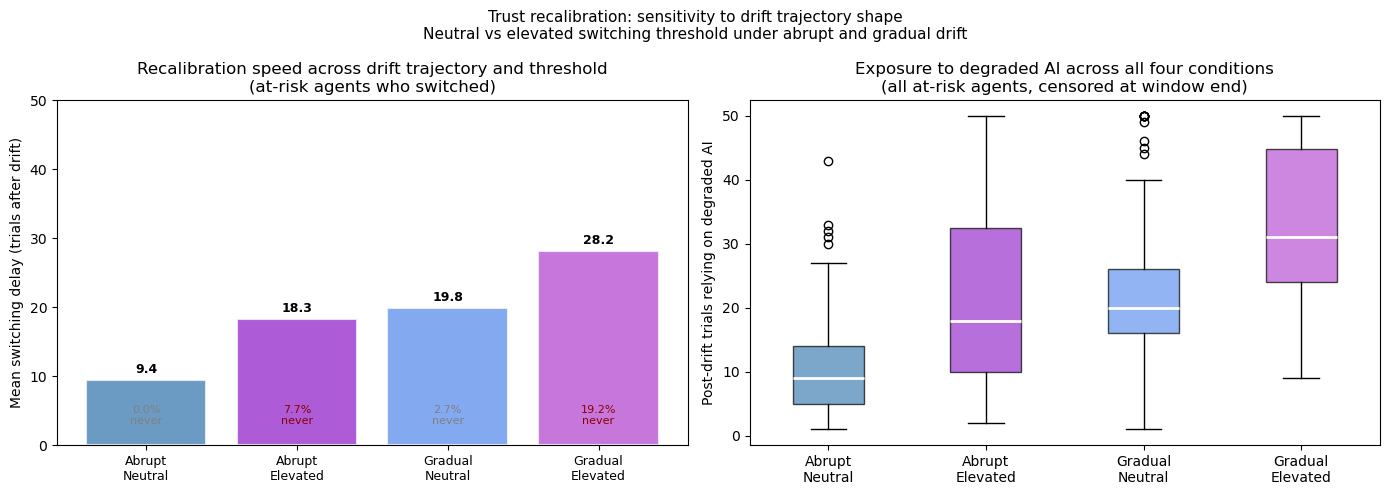

Figure saved.


In [13]:
# --- V4 Plot: 2x2 comparison of drift trajectory and threshold ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

conditions = ['abrupt_neutral', 'abrupt_elevated', 'gradual_neutral', 'gradual_elevated']
labels = ['Abrupt\nNeutral', 'Abrupt\nElevated', 'Gradual\nNeutral', 'Gradual\nElevated']
colors = ['steelblue', 'darkorchid', 'cornflowerblue', 'mediumorchid']

# Left: bar chart of mean switching delay and never-switched %
ax = axes[0]
mean_delays = [s4[k]['mean_delay'] for k in conditions]
never_pcts  = [(1 - s4[k]['switch_rate']) * 100 for k in conditions]

x = np.arange(len(conditions))
ax.bar(x, mean_delays, color=colors, alpha=0.8, edgecolor='white', linewidth=1.5)
ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=9)
ax.set_ylabel('Mean switching delay (trials after drift)')
ax.set_title('Recalibration speed across drift trajectory and threshold\n(at-risk agents who switched)')
ax.set_ylim(0, T - T_drift)

# Annotate bars with never-switched percentages (of at-risk agents)
for i, (delay, pct) in enumerate(zip(mean_delays, never_pcts)):
    ax.text(i, delay + 1, f'{delay:.1f}', ha='center', fontsize=9, fontweight='bold')
    ax.text(i, 3, f'{pct:.1f}%\nnever', ha='center', fontsize=8,
            color='darkred' if pct > 5 else 'gray')

# Right: exposure boxplot, all four conditions
ax = axes[1]
exposure_data = [s4[k]['exposure'] for k in conditions]
bp = ax.boxplot(exposure_data, tick_labels=labels, patch_artist=True,
                medianprops=dict(color='white', linewidth=2))
for box, color in zip(bp['boxes'], colors):
    box.set_facecolor(color)
    box.set_alpha(0.7)

ax.set_ylabel('Post-drift trials relying on degraded AI')
ax.set_title('Exposure to degraded AI across all four conditions\n(all at-risk agents, censored at window end)')

plt.suptitle(
    'Trust recalibration: sensitivity to drift trajectory shape\n'
    'Neutral vs elevated switching threshold under abrupt and gradual drift',
    fontsize=11
)
plt.tight_layout()
plt.show()

# Save
fig.savefig('figures/trust_recalibration_v4.png', dpi=150, bbox_inches='tight')
print("Figure saved.")

### What v4 demonstrates

v4 tests whether the condition difference holds under a more realistic drift trajectory. Abrupt drift (reliability drops from 0.90 to 0.55 at trial 50) is a parsimony choice that gives a clean before/after comparison. Real AI systems more often degrade gradually, so v4 adds a linear decline across a 20-trial window.

The difference holds under both trajectories. Under abrupt drift, the mean switching delay is 9.4 trials (neutral) vs 18.3 (elevated); under gradual drift it is 19.8 vs 28.2. In the elevated-threshold condition, the never-switched rate among at-risk agents climbs from 7.7% to 19.2% when drift is gradual (0.0% to 2.7% for neutral), and mean exposure rises from 21.7 to 33.2 trials. False alarms barely change with drift type (27–28 of 250 neutral vs 0–4 of 250 elevated), as expected, since they happen before the drift begins.

Gradual drift amplifies the recalibration problem rather than reducing it. Early in the drift window each trial carries less diagnostic evidence, so more accumulated error is needed to cross the threshold. Two caveats: under gradual drift, exposure counts from the start of the drift window, when the AI is only slightly degraded; and exposure is censored at the end of the window.